# Activity 7.04 - Top 30 Music YouTube Channels

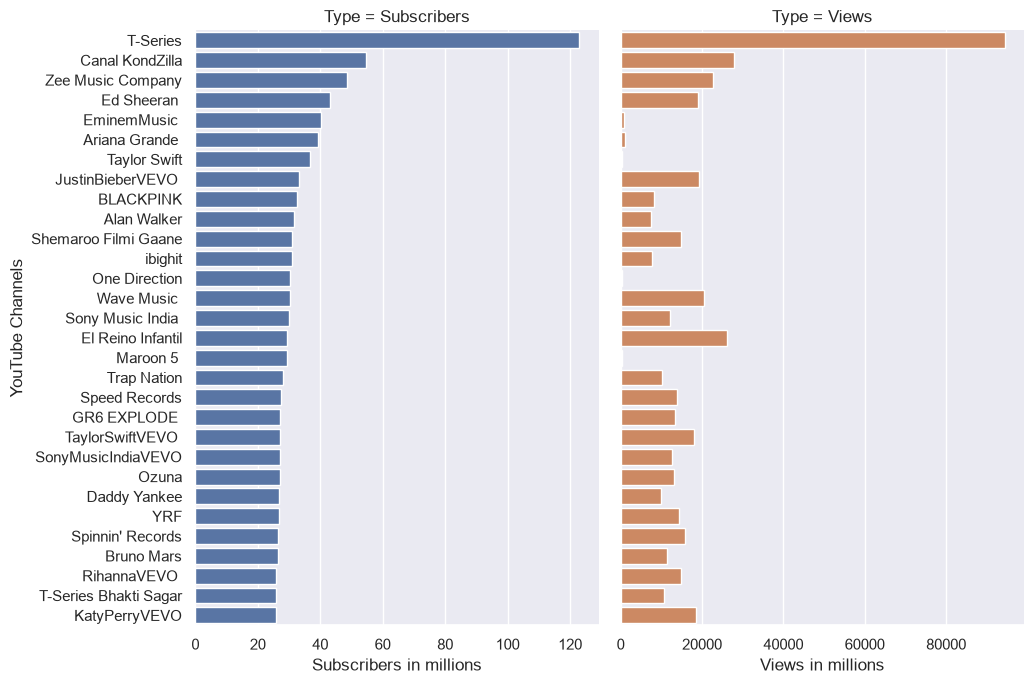

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="darkgrid",
    context="notebook"
)

# 读取数据
youtube = pd.read_csv("YouTube.csv")

# 修改列名
youtube = youtube.rename(
    columns={
        "Subs (in millions)": "Subscribers",
        "Views (in millions)": "Views"
    }
)

# 按订阅人数降序排列
youtube = youtube.sort_values(
    by="Subscribers",
    ascending=False
)

# 转换为长格式
long_data = youtube.melt(
    id_vars="Channel",
    value_vars=["Subscribers", "Views"],
    var_name="Type",
    value_name="Millions"
)

# 保存频道顺序
channel_order = youtube["Channel"].tolist()

# 绘制每个分面中的柱状图
def draw_bars(data, **kwargs):

    # 删除 FacetGrid 自动传入的 color 参数
    kwargs.pop("color", None)

    if data["Type"].iloc[0] == "Subscribers":
        bar_color = "#4C72B0"
    else:
        bar_color = "#DD8452"

    sns.barplot(
        data=data,
        y="Channel",
        x="Millions",
        order=channel_order,
        color=bar_color,
        **kwargs
    )

# 创建 FacetGrid
grid = sns.FacetGrid(
    long_data,
    col="Type",
    col_order=["Subscribers", "Views"],
    sharex=False,
    sharey=True,
    height=7,
    aspect=0.75
)

grid.map_dataframe(draw_bars)

# 设置标题
grid.set_titles("Type = {col_name}")

# 设置坐标轴标题
grid.set_axis_labels(
    "Subscribers in millions",
    "YouTube Channels"
)

# 修改第二个子图的横轴标题
grid.axes[0, 1].set_xlabel("Views in millions")

plt.tight_layout()
plt.show()